# Borjas, *Labor Economics* (9th ed.), Chapter 4: Labor Market Equilibrium

Models only (sections 4-1 to 4-6 and 4-9); the COVID-19 section, empirical immigration studies and "Theory at Work" boxes are skipped. Section 4-7 (high-skill immigration) applies the same immigration surplus logic and is not repeated.

## Summary

| Section | Model | Key result |
|---|---|---|
| 4-1 | One competitive labor market | $S(w) = D(w)$ determines $w^*, E^*$; shifts in $S$ or $D$ move both |
| 4-2 | Two markets, mobile workers | Migration equalizes wages and raises total output |
| 4-3 | Payroll taxes and subsidies | Incidence does not depend on who writes the check; the less elastic side bears more of the tax; deadweight loss |
| 4-4 | Mandated benefits | If workers value the benefit at its full cost, wages fall one-for-one and employment is unchanged |
| 4-5, 4-6 | Immigration | Wages fall, employment of natives falls, and natives as a group gain the immigration surplus (a triangle) |
| 4-9 | Monopsony | $VMP = MC$ of labor; wages and employment below the competitive levels; a binding minimum wage can *raise* employment |

## Assumptions and notation

| Symbol | Meaning | Baseline |
|---|---|---|
| $S(w)$, $D(w)$ | Labor supply and demand curves | |
| $\varepsilon_S$ | Supply elasticity | 0.5 |
| $\delta$ | Demand elasticity (negative) | $-0.75$ |
| $(w_0, E_0)$ | Initial equilibrium | (20, 100) |
| $\tau$ | Payroll tax per hour (negative = subsidy) | |
| $b$, $v$ | Mandated benefit cost per hour and the workers' valuation share | |
| $M$, $N$ | Number of immigrants and natives | |
| $MC_E = w + E\,dw/dE$ | Marginal cost of labor to a monopsonist | |

The supply and demand curves are the market-level versions of the Chapter 2 and 3 results; the demand curve is the $VMP$ curve of the Chapter 3 firm.

**Assumptions**

1. Workers are homogeneous within a market; the wage is the same for everyone (single price).
2. Supply and demand are constant-elasticity curves through the initial equilibrium: $S(w) = E_0 (w/w_0)^{\varepsilon_S}$, $D(w) = E_0 (w/w_0)^{\delta}$.
3. Firms and workers are price takers (except in section 6, the monopsony).
4. A tax or benefit is paid per hour worked.
5. Welfare is measured by areas between the curves (surplus); no income effects on the demand side.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq

from common import *

M = market
S_f, S_inv = curve_from_elasticity(M.w0, M.E0, M.eps_S)
D_f, D_inv = curve_from_elasticity(M.w0, M.E0, M.delta)
print(M)

namespace(w0=20.0, E0=100.0, eps_S=0.5, delta=-0.75)


## 1. Equilibrium in a single labor market (4-1)

Writing $S(w) = s\,w^{\varepsilon_S}$ and $D(w) = d\,w^{\delta}$, equilibrium is

$$\ln w^* = \frac{\ln d - \ln s}{\varepsilon_S - \delta}, \qquad \ln E^* = \ln s + \varepsilon_S \ln w^* .$$

A proportional shift of demand by a factor $g$ ($D \to gD$) changes the equilibrium by

$$\frac{\Delta w}{w}\approx \frac{\ln g}{\varepsilon_S-\delta},\qquad \frac{\Delta E}{E}\approx \frac{\varepsilon_S\ln g}{\varepsilon_S-\delta}$$

(the wage moves by more when both curves are inelastic). The code solves the model numerically for a demand shift and a supply shift and compares with these formulas.

baseline    : w* = 20.000  E* = 100.000
demand +10% : w* = 21.585  E* = 103.886
supply +10% : w* = 18.532  E* = 105.885

Formula, demand +10%: dln(w) = 0.0762, dln(E) = 0.0381


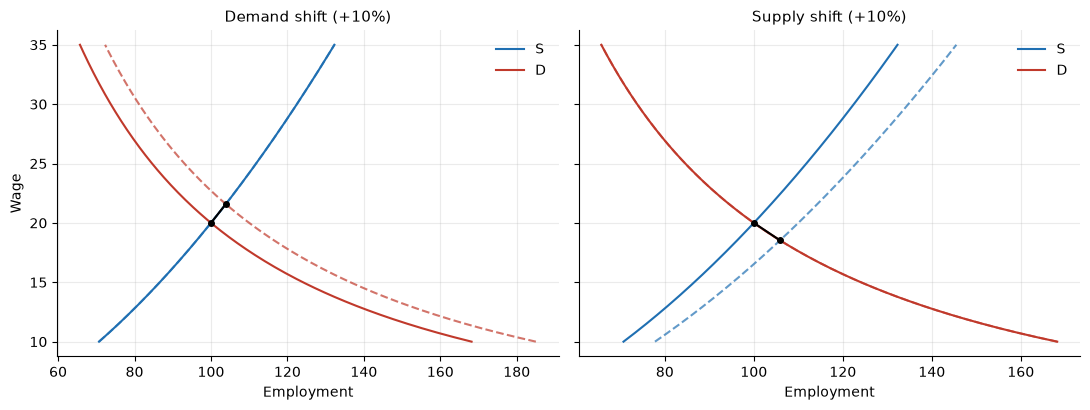

In [2]:
def equilibrium(g_d=1.0, g_s=1.0):
    # solve g_s S(w) = g_d D(w) for w
    w = brentq(lambda x: g_s * S_f(x) - g_d * D_f(x), 1e-3, 1e3)
    return w, float(g_s * S_f(w))


for label, kw in [("baseline", {}), ("demand +10%", {"g_d": 1.10}), ("supply +10%", {"g_s": 1.10})]:
    w_, E_ = equilibrium(**kw)
    print(f"{label:<12}: w* = {w_:6.3f}  E* = {E_:7.3f}")

# Closed-form log-approximation for the demand shift
dlnw = np.log(1.10) / (M.eps_S - M.delta); dlnE = M.eps_S * dlnw
print(f"\nFormula, demand +10%: dln(w) = {dlnw:.4f}, dln(E) = {dlnE:.4f}")
w_d, E_d = equilibrium(g_d=1.10)
assert np.isclose(np.log(w_d / M.w0), dlnw, atol=1e-12) and np.isclose(np.log(E_d / M.E0), dlnE, atol=1e-12)

wg = np.linspace(10, 35, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, kw, title in [(axes[0], {"g_d": 1.10}, "Demand shift (+10%)"), (axes[1], {"g_s": 1.10}, "Supply shift (+10%)")]:
    ax.plot(S_f(wg), wg, color=BLUE, label="S"); ax.plot(D_f(wg), wg, color=RED, label="D")
    gd, gs = kw.get("g_d", 1.0), kw.get("g_s", 1.0)
    ax.plot(gs * S_f(wg), wg, color=BLUE, ls="--", alpha=.7); ax.plot(gd * D_f(wg), wg, color=RED, ls="--", alpha=.7)
    w_, E_ = equilibrium(**kw); ax.plot([M.E0, E_], [M.w0, w_], "o-", color="k", ms=4)
    ax.set_xlabel("Employment"); ax.set_title(title); ax.legend(loc="upper right")
axes[0].set_ylabel("Wage"); plt.tight_layout(); plt.show()

## 2. Equilibrium across labor markets (4-2)

Two regions A and B employ identical workers; total labor $N = N_A + N_B$ is fixed. Region demands are $w_i = VMP_i(E_i)$ with the same elasticity $\delta$ but different level: $w_i(E_i) = \kappa_i\,w_0\,(E_i/E_0)^{1/\delta}$. If workers cannot move, $E_i = N_i$ and wages differ ($w_A > w_B$). With free mobility, workers move until $w_A = w_B$. The shaded area in the figure is the gain in total output (the sum of the $VMP$ areas).

No mobility: w_A = 20.00, w_B = 12.00
Mobility:    E_A = 118.9, E_B = 81.1, common wage = 15.87 (migrants: 18.9)
Gain in total output from migration: 76.1 (about 2.4% of the wage bill)


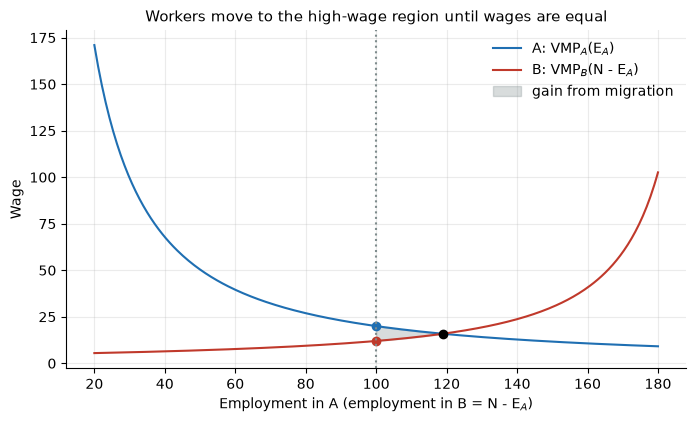

In [3]:
kappa = {"A": 1.0, "B": 0.6}   # B has lower productivity / demand
N_A = N_B = 100.0
N = N_A + N_B

wage = lambda reg, E: kappa[reg] * M.w0 * (E / M.E0) ** (1 / M.delta)
# Before migration
wA0, wB0 = wage("A", N_A), wage("B", N_B)
# After migration: find E_A such that wages are equal
E_A = brentq(lambda e: wage("A", e) - wage("B", N - e), 1.0, N - 1.0)
E_B = N - E_A
w_eq = wage("A", E_A)
assert np.isclose(w_eq, wage("B", E_B))
print(f"No mobility: w_A = {wA0:.2f}, w_B = {wB0:.2f}")
print(f"Mobility:    E_A = {E_A:.1f}, E_B = {E_B:.1f}, common wage = {w_eq:.2f} (migrants: {E_A - N_A:.1f})")

# Gain in total output: output added in A by the migrants minus output lost in B.
# (Only differences matter: the VMP curves are not integrable at E = 0 because 1/delta < -1.)
gain = quad(lambda x: wage("A", x), N_A, E_A)[0] - quad(lambda x: wage("B", x), E_B, N_B)[0]
print(f"Gain in total output from migration: {gain:.1f} (about {100 * gain / (wA0 * N_A + wB0 * N_B):.1f}% of the wage bill)")

fig, ax = plt.subplots(figsize=(8, 4.4))
Eg = np.linspace(20, N - 20, 300)           # E_A on the horizontal axis; E_B = N - E_A
ax.plot(Eg, wage("A", Eg), color=BLUE, label="A: VMP$_A$(E$_A$)")
ax.plot(Eg, wage("B", N - Eg), color=RED, label="B: VMP$_B$(N - E$_A$)")
ax.plot([N_A], [wA0], "o", color=BLUE); ax.plot([N_A], [wB0], "o", color=RED); ax.plot([E_A], [w_eq], "ko")
ax.fill_between(np.linspace(N_A, E_A, 50), wage("B", N - np.linspace(N_A, E_A, 50)), wage("A", np.linspace(N_A, E_A, 50)),
                color=GREY, alpha=0.3, label="gain from migration")
ax.axvline(N_A, color=GREY, ls=":"); ax.set_xlabel("Employment in A (employment in B = N - E$_A$)"); ax.set_ylabel("Wage")
ax.legend(); ax.set_title("Workers move to the high-wage region until wages are equal")
plt.show()

## 3. Payroll taxes and subsidies (4-3)

A tax $\tau$ per hour drives a wedge between what the firm pays, $w_d = w + \tau$, and what the worker receives, $w$. Equilibrium: $S(w) = D(w+\tau)$. It does not matter whether the statute puts the tax on the employer or the worker: both give the same equilibrium. For a small tax, the share of the tax borne by workers is

$$\frac{w_0 - w}{\tau} \approx \frac{|\delta|}{\varepsilon_S + |\delta|},$$

so the *less elastic* side bears more of the burden. A subsidy is a negative tax. The deadweight loss is the area between demand and supply curves over the hours no longer worked:

$$DWL = \int_{E_\tau}^{E_0}\big[D^{-1}(E) - S^{-1}(E)\big]\,dE .$$

In [4]:
def tax_equilibrium(tau, eps_S=M.eps_S, delta=M.delta):
    S = lambda w: M.E0 * (w / M.w0) ** eps_S
    D = lambda w: M.E0 * (w / M.w0) ** delta
    w = brentq(lambda x: S(x) - D(x + tau), 1e-3, 1e3)
    return w, float(S(w))


def tax_summary(tau, eps_S=M.eps_S, delta=M.delta):
    w, E = tax_equilibrium(tau, eps_S, delta)
    S_inv_ = lambda e: M.w0 * (e / M.E0) ** (1 / eps_S)
    D_inv_ = lambda e: M.w0 * (e / M.E0) ** (1 / delta)
    dwl = quad(lambda e: D_inv_(e) - S_inv_(e), E, M.E0)[0] if tau > 0 else quad(lambda e: S_inv_(e) - D_inv_(e), M.E0, E)[0]
    return dict(tau=tau, w=w, w_firm=w + tau, E=E, worker_share=(M.w0 - w) / tau, dwl=dwl)


print(f"{'eps_S':>6} {'tau':>5} {'w_workers':>10} {'w_firm':>8} {'E':>7} {'worker share':>13} {'formula':>8} {'DWL':>7} {'0.5*tau*dE':>11}")
for eps in [0.05, 0.5, 5.0]:
    for tau in [0.2, 2.0]:
        r_ = tax_summary(tau, eps_S=eps)
        formula = abs(M.delta) / (eps + abs(M.delta))
        print(f"{eps:6.2f} {tau:5.1f} {r_['w']:10.3f} {r_['w_firm']:8.3f} {r_['E']:7.2f} {r_['worker_share']:13.3f} {formula:8.3f} "
              f"{r_['dwl']:7.3f} {0.5 * tau * (M.E0 - r_['E']):11.3f}")
        if tau == 0.2:
            assert abs(r_["worker_share"] - formula) < 0.01

# Tax on the worker instead of the employer: net wage w_n, firms pay w_n + tau  (identical equation)
w_a, E_a = tax_equilibrium(2.0)
w_b = brentq(lambda wn: S_f(wn) - D_f(wn + 2.0), 1e-3, 1e3)
assert np.isclose(w_a, w_b)

 eps_S   tau  w_workers   w_firm       E  worker share  formula     DWL  0.5*tau*dE
  0.05   0.2     19.813   20.013   99.95         0.937    0.938   0.005       0.005
  0.05   2.0     18.131   20.131   99.51         0.934    0.938   0.496       0.489
  0.50   0.2     19.880   20.080   99.70         0.599    0.600   0.030       0.030
  0.50   2.0     18.824   20.824   97.02         0.588    0.600   2.978       2.984
  5.00   0.2     19.974   20.174   99.35         0.130    0.130   0.065       0.065
  5.00   2.0     19.750   21.750   93.90         0.125    0.130   5.960       6.097


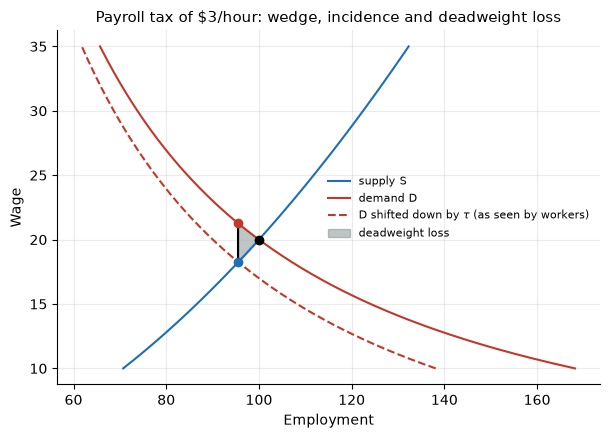

In [5]:
tau = 3.0
w_t, E_t = tax_equilibrium(tau)
wg = np.linspace(10, 35, 200)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.plot(S_f(wg), wg, color=BLUE, label="supply S"); ax.plot(D_f(wg), wg, color=RED, label="demand D")
ax.plot(D_f(wg + tau), wg, color=RED, ls="--", label="D shifted down by $\\tau$ (as seen by workers)")
ax.fill_between([E_t, M.E0], [S_inv(E_t), M.w0], [D_inv(E_t), M.w0], color=GREY, alpha=0.5, label="deadweight loss")
ax.plot([E_t, E_t], [w_t, w_t + tau], color="k"); ax.plot([E_t], [w_t], "o", color=BLUE); ax.plot([E_t], [w_t + tau], "o", color=RED)
ax.plot([M.E0], [M.w0], "ko"); ax.set_xlabel("Employment"); ax.set_ylabel("Wage"); ax.legend(fontsize=8)
ax.set_title(f"Payroll tax of ${tau:.0f}/hour: wedge, incidence and deadweight loss")
plt.show()

## 4. Mandated benefits (4-4)

A mandate costs the employer $b$ per hour. Workers value the benefit at $vb$ (with $0\le v\le1$). The employer's cost is $w+b$; the worker's total compensation is $w+vb$. Equilibrium: $S(w+vb) = D(w+b)$.

* $v=1$ (workers value it at cost): both curves shift down by $b$, the wage falls by exactly $b$ and employment is unchanged: the worker "pays" for the benefit.
* $v=0$: identical to a payroll tax.
* $0<v<1$: employment falls and the triangle of lost hours is smaller than with a tax. The table also reports the extra waste $(1-v)\,b\,E$ from hours that still pay for a benefit workers value below its cost (the book's figure shows only the triangle).

In [6]:
def mandate_equilibrium(b, v):
    w = brentq(lambda x: S_f(x + v * b) - D_f(x + b), 1e-3, 1e3)
    return w, float(D_f(w + b))


b = 3.0
print(f"{'v':>5} {'wage':>8} {'dWage':>8} {'E':>8} {'dE %':>7} {'triangle':>9} {'waste (1-v)bE':>14}")
for v in [0.0, 0.5, 1.0]:
    w_, E_ = mandate_equilibrium(b, v)
    # hours lost: surplus between demand and supply over the hours that disappear
    tri = quad(lambda e: D_inv(e) - S_inv(e), E_, M.E0)[0] if E_ < M.E0 - 1e-9 else 0.0
    print(f"{v:5.1f} {w_:8.3f} {w_ - M.w0:8.3f} {E_:8.2f} {100 * (E_ / M.E0 - 1):7.2f} {tri:9.3f} {(1 - v) * b * E_:14.2f}")

w1_, E1_ = mandate_equilibrium(b, 1.0)
assert np.isclose(E1_, M.E0) and np.isclose(w1_, M.w0 - b)
w0_, E0_ = mandate_equilibrium(b, 0.0)
assert np.isclose(w0_, tax_equilibrium(b)[0]) and np.isclose(E0_, tax_equilibrium(b)[1])
print("\nv = 1: employment unchanged, wage falls by exactly b. v = 0: same as a payroll tax of b.")

    v     wage    dWage        E    dE %  triangle  waste (1-v)bE
  0.0   18.255   -1.745    95.54   -4.46     6.673         286.61
  0.5   17.614   -2.386    97.76   -2.24     1.678         146.64
  1.0   17.000   -3.000   100.00   -0.00     0.000           0.00

v = 1: employment unchanged, wage falls by exactly b. v = 0: same as a payroll tax of b.


## 5. The labor market impact of immigration and the immigration surplus (4-5, 4-6)

Let $N$ natives supply labor and $M$ immigrants arrive. With *inelastic* (vertical) native supply the wage falls along demand: $w_1 = D^{-1}(N+M)$. Natives as a group gain the **immigration surplus**

$$\Pi = \int_{N}^{N+M} D^{-1}(E)\,dE - w_1M \;\approx\; \tfrac12\,(w_0 - w_1)\,M,$$

the extra output (area under the $VMP$ curve) minus the payment to immigrants. Native workers lose $(w_0-w_1)N$ and firms gain more than that. With *elastic* native supply the supply curve shifts right by $M$ and some natives leave employment (the code reports only the wage and native employment effects there; the surplus is computed for the inelastic case). With $\delta=-0.75$ the wage effect of a 10% increase in labor is large; a narrower skill group with $\delta=-2.5$ gives a more modest effect, which is why immigration studies work with skill cells.

 delta  native supply     m       w1    dln w  natives employed   surplus  1/2 dw M
 -0.75      inelastic  0.10   17.613  -0.1271            100.00     11.49     11.93
 -0.75      eps_S=0.5  0.10   18.477  -0.0792             96.12       n/a      7.61
 -2.50      inelastic  0.10   19.252  -0.0381            100.00      3.66      3.74
 -2.50      eps_S=0.5  0.10   19.365  -0.0323             98.40       n/a      3.17


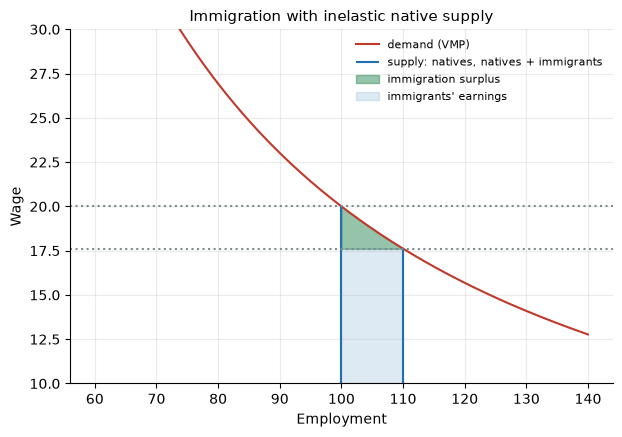

In [7]:
def immigration(m, delta, eps_S=None):
    # N = E0 natives; M = m*N immigrants. delta: demand elasticity; eps_S=None -> inelastic native supply
    Dinv = lambda e: M.w0 * (e / M.E0) ** (1 / delta)
    N_, M_ = M.E0, m * M.E0
    if eps_S is None:
        w1 = Dinv(N_ + M_); E_nat = N_
    else:
        Sf = lambda w: M.E0 * (w / M.w0) ** eps_S
        w1 = brentq(lambda w: Sf(w) + M_ - M.E0 * (w / M.w0) ** delta, 1e-3, 1e3); E_nat = Sf(w1)
    surplus = quad(Dinv, E_nat if eps_S is None else E_nat, E_nat + M_)[0] - w1 * M_ if eps_S is None else None
    return w1, E_nat, M_, surplus


print(f"{'delta':>6} {'native supply':>14} {'m':>5} {'w1':>8} {'dln w':>8} {'natives employed':>17} {'surplus':>9} {'1/2 dw M':>9}")
for delta in [M.delta, -2.5]:
    for eps in [None, M.eps_S]:
        w1, E_nat, M_, sur = immigration(0.10, delta, eps)
        s_str = f"{sur:9.2f}" if sur is not None else "      n/a"
        approx = 0.5 * (M.w0 - w1) * M_
        print(f"{delta:6.2f} {'inelastic' if eps is None else f'eps_S={eps}':>14} {0.10:5.2f} {w1:8.3f} {np.log(w1 / M.w0):8.4f} "
              f"{E_nat:17.2f} {s_str} {approx:9.2f}")

# Check: inelastic supply, wage change = D^{-1}(N+M)/w0
w1, _, M_, sur = immigration(0.10, M.delta)
assert np.isclose(w1, M.w0 * 1.1 ** (1 / M.delta)) and abs(sur - 0.5 * (M.w0 - w1) * M_) / sur < 0.05

Eg = np.linspace(60, 140, 200)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.plot(Eg, D_inv(Eg), color=RED, label="demand (VMP)")
ax.vlines([M.E0, M.E0 + M_], 0, [M.w0, w1], color=BLUE, label="supply: natives, natives + immigrants")
ax.axhline(M.w0, color=GREY, ls=":"); ax.axhline(w1, color=GREY, ls=":")
xs = np.linspace(M.E0, M.E0 + M_, 60)
ax.fill_between(xs, w1, D_inv(xs), color=GREEN, alpha=0.5, label="immigration surplus")
ax.fill_between(xs, 0, w1, color=BLUE, alpha=0.15, label="immigrants' earnings")
ax.set_ylim(10, 30); ax.set_xlabel("Employment"); ax.set_ylabel("Wage"); ax.legend(fontsize=8)
ax.set_title("Immigration with inelastic native supply")
plt.show()

## 6. Monopsony (4-9)

A single employer faces the market supply curve $w = S^{-1}(E)$. To hire one more worker it must raise the wage for *all* workers, so the marginal cost of labor lies above the supply curve:

$$MC_E = w + E\,\frac{dw}{dE} = w\Big(1 + \frac{1}{\varepsilon_S}\Big).$$

The profit-maximizing monopsonist hires where $VMP_E = MC_E$ and pays the wage on the *supply* curve at that employment: $w_m = \dfrac{\varepsilon_S}{1+\varepsilon_S}\,VMP_E < VMP_E$. With constant-elasticity curves through $(E_0, w_0)$,

$$E_m = E_0\,\Big(1+\tfrac{1}{\varepsilon_S}\Big)^{\frac{1}{1/\delta - 1/\varepsilon_S}} .$$

A binding minimum wage between $w_m$ and the competitive wage makes the labor supply curve flat at $w_{min}$ up to $S(w_{min})$, so $MC_E = w_{min}$ over that range and **employment rises**; above the competitive wage employment falls along $D$. (For a firm-level supply elasticity this section uses $\varepsilon_S = 2$.)

Competitive: E = 100.0, w = 20.00
Monopsony:   E = 80.2, w = 17.91, VMP = 26.86, markdown w/VMP = 0.667 (eps/(1+eps) = 0.667)
Deadweight loss: 82.60


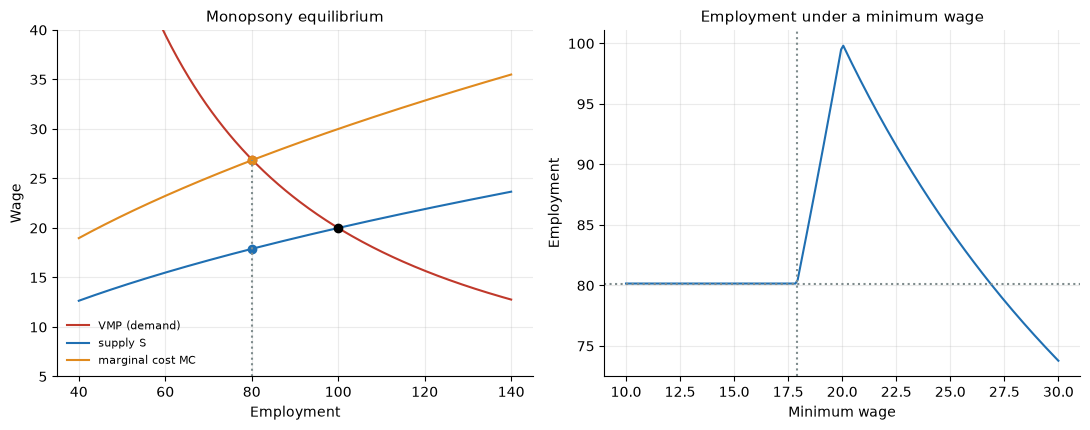

In [8]:
eps_m = 2.0     # firm-level supply elasticity facing the monopsonist
S_m, S_m_inv = curve_from_elasticity(M.w0, M.E0, eps_m)
VMP = lambda E: M.w0 * (E / M.E0) ** (1 / M.delta)
MC = lambda E: S_m_inv(E) * (1 + 1 / eps_m)

E_m = M.E0 * (1 + 1 / eps_m) ** (1 / (1 / M.delta - 1 / eps_m))
E_m_num = brentq(lambda e: VMP(e) - MC(e), 1.0, 1000.0)
assert np.isclose(E_m, E_m_num)
w_m = float(S_m_inv(E_m))
print(f"Competitive: E = {M.E0:.1f}, w = {M.w0:.2f}")
print(f"Monopsony:   E = {E_m:.1f}, w = {w_m:.2f}, VMP = {VMP(E_m):.2f}, markdown w/VMP = {w_m / VMP(E_m):.3f} (eps/(1+eps) = {eps_m / (1 + eps_m):.3f})")
dwl_m = quad(lambda e: VMP(e) - S_m_inv(e), E_m, M.E0)[0]
print(f"Deadweight loss: {dwl_m:.2f}")

def employment_with_min_wage(wmin):
    # supply is flat at wmin up to S(wmin); firm hires S(wmin) if VMP at that level exceeds wmin, else where VMP = wmin
    if wmin <= w_m:
        return E_m
    return min(float(S_m(wmin)), float(M.E0 * (wmin / M.w0) ** M.delta))

mw = np.linspace(10, 30, 200)
Emw = np.array([employment_with_min_wage(x) for x in mw])
assert Emw.max() > E_m and np.isclose(mw[np.argmax(Emw)], M.w0, atol=0.2)

Eg = np.linspace(40, 140, 300)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.plot(Eg, VMP(Eg), color=RED, label="VMP (demand)"); ax.plot(Eg, S_m_inv(Eg), color=BLUE, label="supply S")
ax.plot(Eg, MC(Eg), color=ORANGE, label="marginal cost MC")
ax.plot([E_m], [w_m], "o", color=BLUE); ax.plot([E_m], [VMP(E_m)], "o", color=RED); ax.plot([E_m], [MC(E_m)], "o", color=ORANGE)
ax.plot([M.E0], [M.w0], "ko"); ax.vlines(E_m, 0, VMP(E_m), color=GREY, ls=":"); ax.set_ylim(5, 40)
ax.set_xlabel("Employment"); ax.set_ylabel("Wage"); ax.legend(fontsize=8); ax.set_title("Monopsony equilibrium")
axes[1].plot(mw, Emw, color=BLUE); axes[1].axhline(E_m, color=GREY, ls=":"); axes[1].axvline(w_m, color=GREY, ls=":")
axes[1].set_xlabel("Minimum wage"); axes[1].set_ylabel("Employment"); axes[1].set_title("Employment under a minimum wage")
plt.tight_layout(); plt.show()

## Check list

* One market: numerical equilibrium equals the closed-form log solution.
* Tax incidence: worker share $\to |\delta|/(\varepsilon_S+|\delta|)$ for small $\tau$; a payroll tax on the worker gives the same equilibrium.
* Mandate with $v=1$: wage falls by $b$, employment unchanged; $v=0$: same as a tax.
* Immigration surplus $\approx \tfrac12 (w_0-w_1) M$.
* Monopsony: $w_m/VMP = \varepsilon_S/(1+\varepsilon_S)$; employment under a minimum wage peaks at the competitive wage.